# Task 1.1 — Individual Recommendation Models

**Goal:** evaluate 11 RecBole recommenders on MovieLens 100K using a consistent full-ranking protocol.  
**Selection metric:** validation MRR@10. **Reported metrics:** Recall, MRR, NDCG, Hit, and Precision at 10.

Run from top to bottom. Existing CSV rows are reused by default; set `RERUN_ALL = True` if configurations or dataset settings change. EASE and SLIMElastic are fitted during initialization and evaluated explicitly on the validation split.

## 1. Imports and paths

## Environment Setup

This experiment uses Python 3.10 and RecBole 1.2.1.

To reproduce the environment:

1. Create a Python 3.10 virtual environment.
2. Activate the environment.
3. Install dependencies using `pip install -r requirements.txt`.
4. Select the environment as the Jupyter kernel.

The experiment uses CPU execution for portability.

In [12]:
# Env verification
import sys
import platform
from importlib.metadata import version

EXPECTED = {
    "recbole": "1.2.1",
    "numpy": "1.23.5",
    "pandas": "1.5.3",
    "scipy": "1.10.1",
    "scikit-learn": "1.2.2",
    "torch": "2.2.2",
}

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("Architecture:", platform.machine())

assert sys.version_info[:2] == (3, 10), "Python 3.10 required"

for package, expected in EXPECTED.items():
    installed = version(package)
    status = "OK" if installed == expected else "DIFFERENT"
    print(f"{package:15} {installed:12} {status}")

Python: 3.10.10
OS: macOS-14.3-arm64-arm-64bit
Architecture: arm64
recbole         1.2.1        OK
numpy           1.23.5       OK
pandas          1.5.3        OK
scipy           1.10.1       OK
scikit-learn    1.2.2        OK
torch           2.14.1       DIFFERENT


In [ ]:
import os
from pathlib import Path

# Required only for loading checkpoints generated by a trusted local run.
os.environ.setdefault("TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from recbole.quick_start import run_recbole
from recbole.config import Config
from recbole.data import create_dataset, data_preparation
from recbole.utils import get_model, get_trainer, init_seed


def find_project_root(start: Path) -> Path:
    for directory in (start, *start.parents):
        if (directory / "run_recbole.py").exists():
            return directory
    raise FileNotFoundError("Could not find project root (run_recbole.py)")


ROOT = find_project_root(Path.cwd().resolve())
DATASET = "ml-100k"
SEED = 2020
CONFIG_DIR = ROOT / "recbole" / "config"
DATA_DIR = ROOT / "dataset"
CHECKPOINT_DIR = ROOT / "saved"
RESULTS_DIR = ROOT / "group_18" / "results" / "task_1_1"
RESULTS_FILE = RESULTS_DIR / "baseline_results.csv"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", ROOT)
print("Dataset:", DATA_DIR / DATASET)
print("Results:", RESULTS_FILE)

Project: /Users/randy/Desktop/Recommender Systems/New Final Project/RecBole_DSAIT4335_Group_18
Dataset: /Users/randy/Desktop/Recommender Systems/New Final Project/RecBole_DSAIT4335_Group_18/dataset/ml-100k
Results: /Users/randy/Desktop/Recommender Systems/New Final Project/RecBole_DSAIT4335_Group_18/group_18/results/task_1_1/baseline_results.csv


## 2. Dataset overview
RecBole reads the atomic files from the project dataset directory and creates the splits specified in each YAML configuration.

In [14]:
inter_path = DATA_DIR / DATASET / f"{DATASET}.inter"
interactions = pd.read_csv(inter_path, sep="\t")
print(f"Interactions: {len(interactions):,}")
print(f"Users: {interactions.iloc[:, 0].nunique():,}")
print(f"Items: {interactions.iloc[:, 1].nunique():,}")
display(interactions.head())

Interactions: 100,000
Users: 943
Items: 1,682


,user_id:token,item_id:token,rating:float,timestamp:float
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## 3. Experimental setup
All model YAML files should specify an 80/10/10 random split grouped by user, full-ranking evaluation, `topk: [10]`, and `valid_metric: MRR@10`. The model-specific YAML files remain the source of truth for hyperparameters.

In [15]:
MODELS = [
    "Random", "Pop", "BPR", "EASE", "ItemKNN", "UserKNN",
    "FISM", "SLIMElastic", "NeuMF", "LightGCN", "NGCF",
]

# RecBole implements UserKNN using ItemKNN with knn_method: user in YAML.
MODEL_ALIASES = {"UserKNN": "ItemKNN"}
TRADITIONAL_MODELS = {"EASE", "SLIMElastic"}
METRICS = ["recall@10", "mrr@10", "ndcg@10", "hit@10", "precision@10"]
RERUN_ALL = False  # Set True after changing dataset, YAML, or evaluation settings.


def model_config_path(name: str) -> Path:
    return CONFIG_DIR / name / f"{DATASET}.yaml"


def common_config() -> dict:
    return {
        "seed": SEED,
        "reproducibility": True,
        "use_gpu": False,
        "data_path": str(DATA_DIR),
        "checkpoint_dir": str(CHECKPOINT_DIR),
    }


missing_configs = [name for name in MODELS if not model_config_path(name).is_file()]
if missing_configs:
    raise FileNotFoundError(f"Missing YAML configurations: {missing_configs}")

# Check that the UserKNN YAML selects user-based neighbors.
user_knn_yaml = model_config_path("UserKNN").read_text()
if "knn_method: user" not in user_knn_yaml and "knn_method: 'user'" not in user_knn_yaml and 'knn_method: "user"' not in user_knn_yaml:
    print("WARNING: Verify UserKNN YAML contains knn_method: user")

print("All model YAML files found.")

All model YAML files found.


## 4. Reusable experiment functions
Each function has one job: execute a model, evaluate traditional models, normalize results, or persist results. EASE and SLIMElastic are not trained with gradients; their item weights are constructed when the model is initialized.

In [16]:
def evaluate_traditional_validation(name: str) -> dict:
    """Evaluate the already-fitted traditional model on the validation split."""
    config = Config(
        model=MODEL_ALIASES.get(name, name),
        dataset=DATASET,
        config_file_list=[str(model_config_path(name))],
        config_dict=common_config(),
    )
    init_seed(config["seed"], config["reproducibility"])
    dataset = create_dataset(config)
    train_data, valid_data, _test_data = data_preparation(config, dataset)
    model = get_model(config["model"])(config, train_data.dataset).to(config["device"])
    trainer = get_trainer(config["MODEL_TYPE"], config["model"])(config, model)
    return trainer.evaluate(valid_data, load_best_model=False)


def run_model(name: str) -> dict:
    """Execute a RecBole baseline, adding validation for traditional models."""
    actual_model = MODEL_ALIASES.get(name, name)
    result = run_recbole(
        model=actual_model,
        dataset=DATASET,
        config_file_list=[str(model_config_path(name))],
        config_dict=common_config(),
        saved=name not in TRADITIONAL_MODELS,
    )
    if name in TRADITIONAL_MODELS:
        valid_result = evaluate_traditional_validation(name)
        result["best_valid_result"] = valid_result
        result["best_valid_score"] = valid_result["mrr@10"]
    return result


def format_result(name: str, result: dict) -> dict:
    """Convert RecBole results into one flat, consistent CSV row."""
    valid = result.get("best_valid_result") or {}
    test = result.get("test_result") or {}
    if any(metric not in valid or metric not in test for metric in METRICS):
        raise ValueError(f"{name}: missing required validation or test metrics")
    return {
        "model": name,
        "recbole_model": MODEL_ALIASES.get(name, name),
        "best_valid_score": float(valid["mrr@10"]),
        **{f"valid_{metric}": valid[metric] for metric in METRICS},
        **{f"test_{metric}": test[metric] for metric in METRICS},
    }


def save_results(rows: list[dict]) -> None:
    """Persist completed runs after each model."""
    pd.DataFrame(rows).to_csv(RESULTS_FILE, index=False)


def load_results() -> list[dict]:
    """Resume completed runs unless a full rerun is requested."""
    if RERUN_ALL or not RESULTS_FILE.exists():
        return []
    return pd.read_csv(RESULTS_FILE).to_dict("records")

## 5. Run experiments
The runner orchestrates execution only. Successful runs are written immediately, and failures are recorded without stopping the other models. **Resume caution:** an existing CSV is not automatically invalidated when configs change; use `RERUN_ALL = True` for a clean experiment.

In [17]:
all_results = load_results()
completed = {row["model"] for row in all_results}
failures = []

for name in MODELS:
    if name in completed:
        print(f"SKIP {name}: already in CSV")
        continue

    print(f"RUN  {name}")
    try:
        row = format_result(name, run_model(name))
        all_results.append(row)
        save_results(all_results)
        completed.add(name)
        print(f"DONE {name}: valid MRR@10={row['valid_mrr@10']:.4f}")
    except Exception as exc:
        failures.append({"model": name, "error": str(exc)})
        print(f"FAIL {name}: {exc}")

results_df = pd.DataFrame(all_results)
display(results_df)
if failures:
    display(pd.DataFrame(failures))

SKIP Random: already in CSV
SKIP Pop: already in CSV
SKIP BPR: already in CSV
SKIP EASE: already in CSV
SKIP ItemKNN: already in CSV
SKIP UserKNN: already in CSV
SKIP FISM: already in CSV
SKIP SLIMElastic: already in CSV
SKIP NeuMF: already in CSV
SKIP LightGCN: already in CSV
SKIP NGCF: already in CSV


,model,recbole_model,best_valid_score,valid_recall@10,valid_mrr@10,valid_ndcg@10,valid_hit@10,valid_precision@10,test_recall@10,test_mrr@10,test_ndcg@10,test_hit@10,test_precision@10
0,Random,Random,0.0233,0.0074,0.0233,0.0094,0.0679,0.0072,0.0061,0.0157,0.0068,0.0541,0.0058
1,Pop,Pop,0.1781,0.0831,0.1781,0.0932,0.4602,0.0742,0.0880,0.1951,0.1034,0.4698,0.0829
2,BPR,BPR,0.3474,0.1810,0.3474,0.1994,0.6808,0.1382,0.2085,0.4304,0.2494,0.7275,0.1670
3,ItemKNN,ItemKNN,0.3779,0.2058,0.3779,0.2213,0.7328,0.1554,0.2470,0.4623,0.2834,0.7847,0.1931
4,UserKNN,ItemKNN,0.3992,0.2102,0.3992,0.2345,0.7402,0.1567,0.2442,0.4834,0.2873,0.7805,0.1885
5,FISM,FISM,0.2305,0.1105,0.2305,0.1208,0.5355,0.0912,0.1220,0.2669,0.1409,0.5620,0.1055
6,NeuMF,NeuMF,0.3609,0.2027,0.3609,0.2138,0.7402,0.1504,0.2273,0.4488,0.2673,0.7646,0.1832
7,LightGCN,LightGCN,0.2572,0.1258,0.2572,0.1363,0.5726,0.0943,0.1388,0.2963,0.1586,0.6098,0.1104
8,NGCF,NGCF,0.2675,0.1384,0.2675,0.1526,0.6045,0.1173,0.1532,0.3109,0.1829,0.6363,0.1402
9,EASE,EASE,0.4201,0.2389,0.4201,0.2563,0.7847,0.1755,0.2805,0.5277,0.3295,0.8197,0.2206


## 6. Validate and compare results
For model selection and Task 1.2 tuning, use **validation** MRR@10. Test scores are for final reporting, not choosing hyperparameters.

In [18]:
results_df = pd.read_csv(RESULTS_FILE)
required = [f"{split}_{metric}" for split in ("valid", "test") for metric in METRICS]
assert results_df["model"].is_unique, "Duplicate model rows"
assert set(results_df["model"]) == set(MODELS), "Missing or unexpected models"
assert results_df[required].notna().all().all(), "Missing evaluation metrics"

comparison = results_df[["model", "valid_mrr@10", *[f"test_{m}" for m in METRICS]]]
comparison = comparison.sort_values("valid_mrr@10", ascending=False)
display(comparison.round(4))

,model,valid_mrr@10,test_recall@10,test_mrr@10,test_ndcg@10,test_hit@10,test_precision@10
10,SLIMElastic,0.4214,0.2750,0.5231,0.3236,0.8123,0.2165
9,EASE,0.4201,0.2805,0.5277,0.3295,0.8197,0.2206
4,UserKNN,0.3992,0.2442,0.4834,0.2873,0.7805,0.1885
3,ItemKNN,0.3779,0.2470,0.4623,0.2834,0.7847,0.1931
6,NeuMF,0.3609,0.2273,0.4488,0.2673,0.7646,0.1832
2,BPR,0.3474,0.2085,0.4304,0.2494,0.7275,0.1670
8,NGCF,0.2675,0.1532,0.3109,0.1829,0.6363,0.1402
7,LightGCN,0.2572,0.1388,0.2963,0.1586,0.6098,0.1104
5,FISM,0.2305,0.1220,0.2669,0.1409,0.5620,0.1055
1,Pop,0.1781,0.0880,0.1951,0.1034,0.4698,0.0829


## 7. Visualize baseline performance

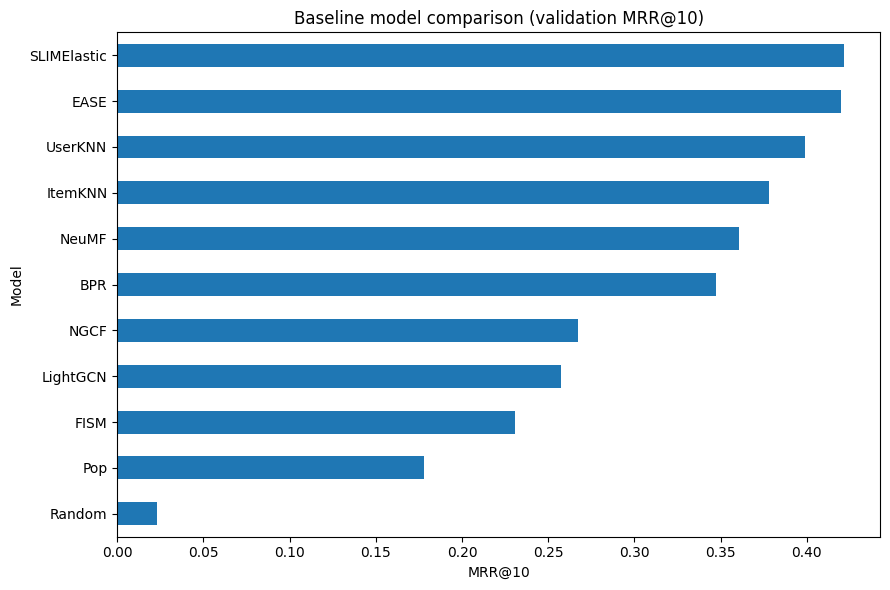

In [19]:
plot_data = comparison.sort_values("valid_mrr@10")
ax = plot_data.plot.barh(x="model", y="valid_mrr@10", figsize=(9, 6), legend=False)
ax.set(title="Baseline model comparison (validation MRR@10)", xlabel="MRR@10", ylabel="Model")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "validation_mrr_comparison.png", dpi=160)
plt.show()